# 07 Simple Linear Regression

This notebook is a starting point for simple linear regression experiments on the encoded ElectraHub dataset.

Suggested flow:
- load the encoded training and test sets
- fit simple linear regression models
- evaluate model performance
- compare feature choices

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
import pandas as pd

train_path = Path("../data/processed/ElectraHub_train_encoded.csv")
test_path = Path("../data/processed/ElectraHub_test_encoded.csv")

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print(f"Train path: {train_path}")
print(f"Test path: {test_path}")
print(f"Train rows: {len(train_df)}")
print(f"Test rows: {len(test_df)}")

Train path: ../data/processed/ElectraHub_train_encoded.csv
Test path: ../data/processed/ElectraHub_test_encoded.csv
Train rows: 2400
Test rows: 600


In [3]:
train_df.head()

   Product_Age_Months  ...  Campaign_Type_Social Media
0                   3  ...                       False
1                   7  ...                       False
2                  16  ...                       False
3                   9  ...                       False
4                   5  ...                       False

[5 rows x 20 columns]

## Simple Linear Regression

Use this section to fit one predictor at a time and compare performance.

### Sales vs Campaign Engagement Score

This model uses Campaign_Engagement_Score as the single predictor for Sales.

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.521
Model:                            OLS   Adj. R-squared:                  0.521
Method:                 Least Squares   F-statistic:                     2608.
Date:                Thu, 28 May 2026   Prob (F-statistic):               0.00
Time:                        10:19:55   Log-Likelihood:                -23777.
No. Observations:                2400   AIC:                         4.756e+04
Df Residuals:                    2398   BIC:                         4.757e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

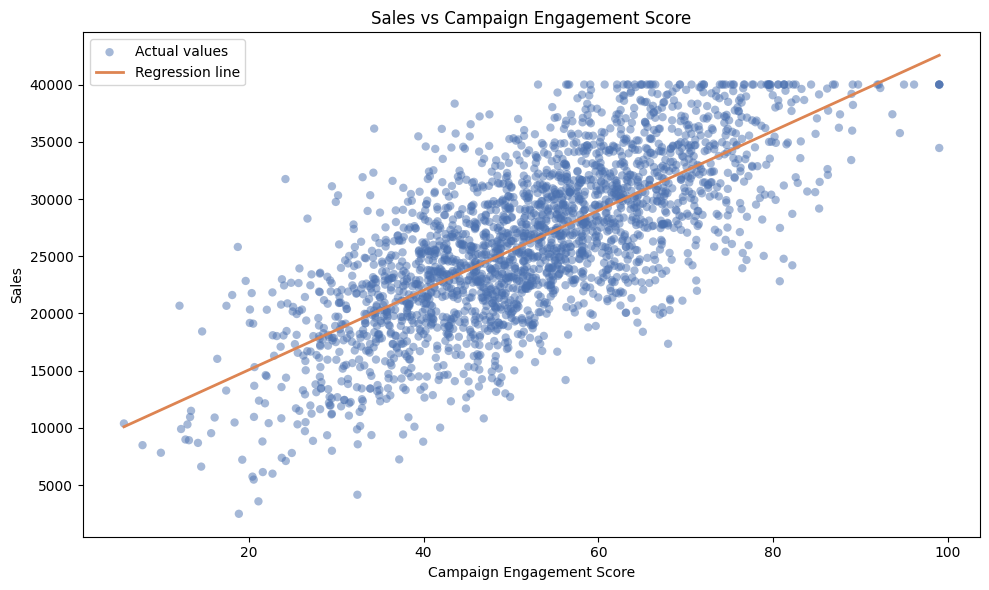

In [6]:
x_train = train_df[["Campaign_Engagement_Score"]]
y_train = train_df["Sales"]
x_test = test_df[["Campaign_Engagement_Score"]]
y_test = test_df["Sales"]

x_train_with_constant = sm.add_constant(x_train)
x_test_with_constant = sm.add_constant(x_test)

model = sm.OLS(y_train, x_train_with_constant).fit()
predictions = model.predict(x_test_with_constant)

residuals = y_test - predictions
rmse = np.sqrt(np.mean(residuals ** 2))
mae = np.mean(np.abs(residuals))

print(model.summary())
print("\nKey Metrics")
print(f"Intercept: {model.params['const']:.4f}")
print(f"Coefficient for Campaign_Engagement_Score: {model.params['Campaign_Engagement_Score']:.4f}")
print(f"P-value for Campaign_Engagement_Score: {model.pvalues['Campaign_Engagement_Score']:.6f}")
print(f"R-squared: {model.rsquared:.4f}")
print(f"F-statistic: {model.fvalue:.4f}")
print(f"RMSE on test set: {rmse:.4f}")
print(f"MAE on test set: {mae:.4f}")

plt.figure(figsize=(10, 6))
plt.scatter(x_train["Campaign_Engagement_Score"], y_train, alpha=0.5, color="#4C72B0", edgecolors="none", label="Actual values")
x_line = np.linspace(x_train["Campaign_Engagement_Score"].min(), x_train["Campaign_Engagement_Score"].max(), 100)
y_line = model.params['const'] + model.params['Campaign_Engagement_Score'] * x_line
plt.plot(x_line, y_line, color="#DD8452", linewidth=2, label="Regression line")
plt.title("Sales vs Campaign Engagement Score")
plt.xlabel("Campaign Engagement Score")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

## Linear Regression Assumption Checks

These checks help us understand whether the simple linear regression fit is reasonable.


Assumption checks
Durbin-Watson: 1.9995 (values near 2 suggest no autocorrelation)
Breusch-Pagan p-value: 0.039346 (small p-value suggests heteroscedasticity)
Jarque-Bera p-value: 0.615249 (high p-value suggests residuals are approximately normal)
Mean residual: -0.000000 (should be close to 0)


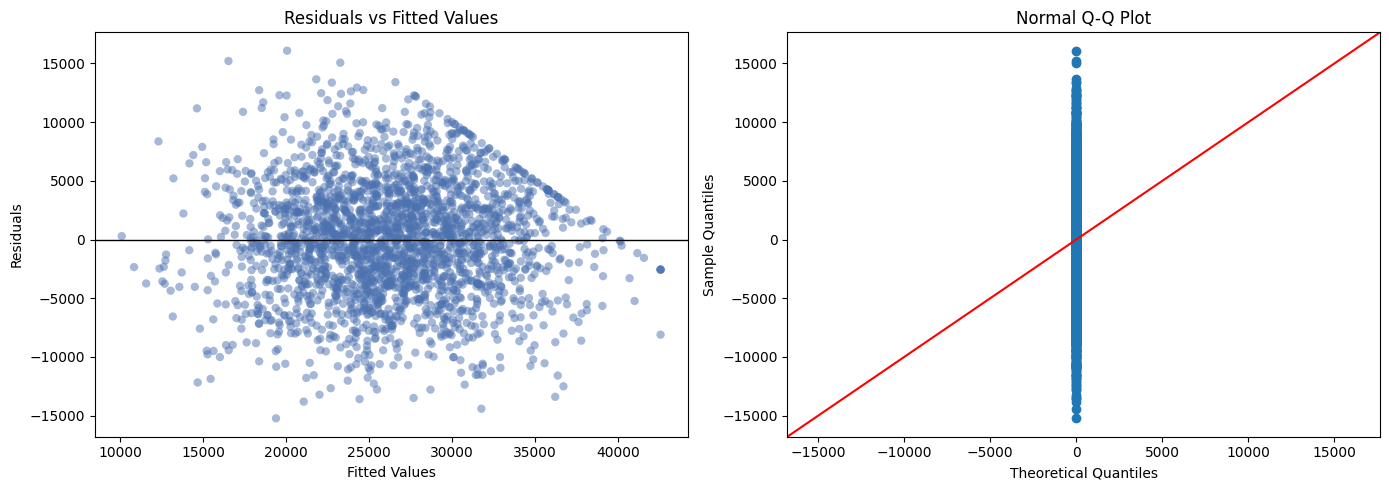

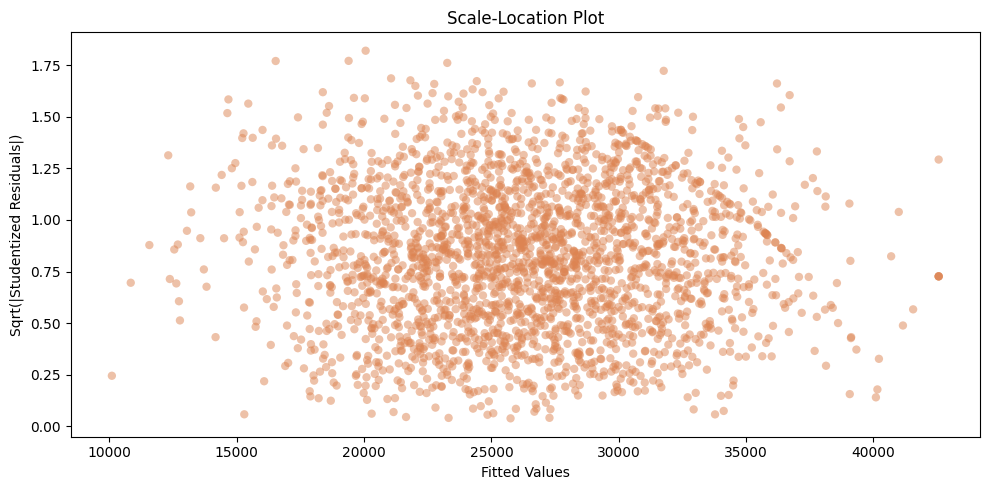

In [8]:
residuals = model.resid
fitted_values = model.fittedvalues
studentized_residuals = model.get_influence().resid_studentized_internal

durbin_watson = sm.stats.stattools.durbin_watson(residuals)
breusch_pagan = het_breuschpagan(residuals, x_train_with_constant)
jarque_bera = sm.stats.stattools.jarque_bera(residuals)

print("Assumption checks")
print(f"Durbin-Watson: {durbin_watson:.4f} (values near 2 suggest no autocorrelation)")
print(f"Breusch-Pagan p-value: {breusch_pagan[1]:.6f} (small p-value suggests heteroscedasticity)")
print(f"Jarque-Bera p-value: {jarque_bera[1]:.6f} (high p-value suggests residuals are approximately normal)")
print(f"Mean residual: {residuals.mean():.6f} (should be close to 0)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(fitted_values, residuals, alpha=0.5, color="#4C72B0", edgecolors="none")
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("Residuals vs Fitted Values")
axes[0].set_xlabel("Fitted Values")
axes[0].set_ylabel("Residuals")

sm.qqplot(residuals, line="45", ax=axes[1])
axes[1].set_title("Normal Q-Q Plot")

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.scatter(fitted_values, np.sqrt(np.abs(studentized_residuals)), alpha=0.5, color="#DD8452", edgecolors="none")
plt.title("Scale-Location Plot")
plt.xlabel("Fitted Values")
plt.ylabel("Sqrt(|Studentized Residuals|)")
plt.tight_layout()
plt.show()


### Sales vs Advertising Expenditure

This model uses Advertising_Expenditure as the single predictor for Sales.


                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.421
Model:                            OLS   Adj. R-squared:                  0.421
Method:                 Least Squares   F-statistic:                     1743.
Date:                Thu, 28 May 2026   Prob (F-statistic):          8.61e-287
Time:                        10:19:56   Log-Likelihood:                -24005.
No. Observations:                2400   AIC:                         4.801e+04
Df Residuals:                    2398   BIC:                         4.802e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                   -7

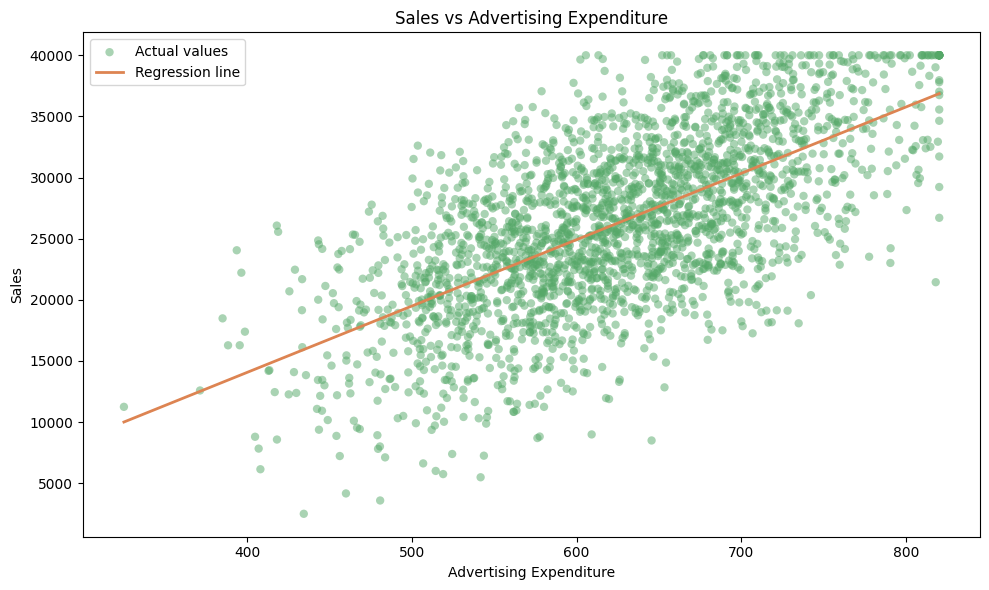

In [10]:
adv_x_train = train_df[["Advertising_Expenditure"]]
adv_y_train = train_df["Sales"]
adv_x_test = test_df[["Advertising_Expenditure"]]
adv_y_test = test_df["Sales"]

adv_x_train_with_constant = sm.add_constant(adv_x_train)
adv_x_test_with_constant = sm.add_constant(adv_x_test)

adv_model = sm.OLS(adv_y_train, adv_x_train_with_constant).fit()
adv_predictions = adv_model.predict(adv_x_test_with_constant)

adv_residuals = adv_y_test - adv_predictions
adv_rmse = np.sqrt(np.mean(adv_residuals ** 2))
adv_mae = np.mean(np.abs(adv_residuals))

print(adv_model.summary())
print("\nKey Metrics")
print(f"Intercept: {adv_model.params['const']:.4f}")
print(f"Coefficient for Advertising_Expenditure: {adv_model.params['Advertising_Expenditure']:.4f}")
print(f"P-value for Advertising_Expenditure: {adv_model.pvalues['Advertising_Expenditure']:.6f}")
print(f"R-squared: {adv_model.rsquared:.4f}")
print(f"F-statistic: {adv_model.fvalue:.4f}")
print(f"RMSE on test set: {adv_rmse:.4f}")
print(f"MAE on test set: {adv_mae:.4f}")

plt.figure(figsize=(10, 6))
plt.scatter(adv_x_train["Advertising_Expenditure"], adv_y_train, alpha=0.5, color="#55A868", edgecolors="none", label="Actual values")
adv_x_line = np.linspace(adv_x_train["Advertising_Expenditure"].min(), adv_x_train["Advertising_Expenditure"].max(), 100)
adv_y_line = adv_model.params['const'] + adv_model.params['Advertising_Expenditure'] * adv_x_line
plt.plot(adv_x_line, adv_y_line, color="#DD8452", linewidth=2, label="Regression line")
plt.title("Sales vs Advertising Expenditure")
plt.xlabel("Advertising Expenditure")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

## Advertising Expenditure Assumption Checks

These checks help us understand whether the Advertising_Expenditure simple linear regression fit is reasonable.


Advertising Expenditure assumption checks
Durbin-Watson: 1.9893 (values near 2 suggest no autocorrelation)
Breusch-Pagan p-value: 0.056557 (small p-value suggests heteroscedasticity)
Jarque-Bera p-value: 0.000345 (small p-value suggests residuals are not approximately normal)
Mean residual: 0.000000 (should be close to 0)


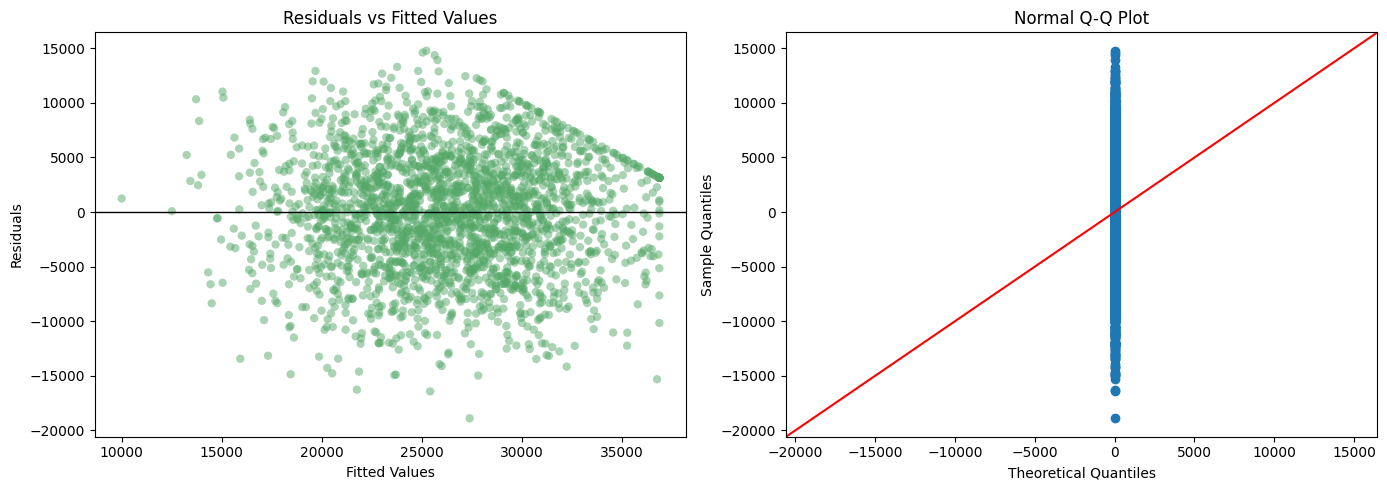

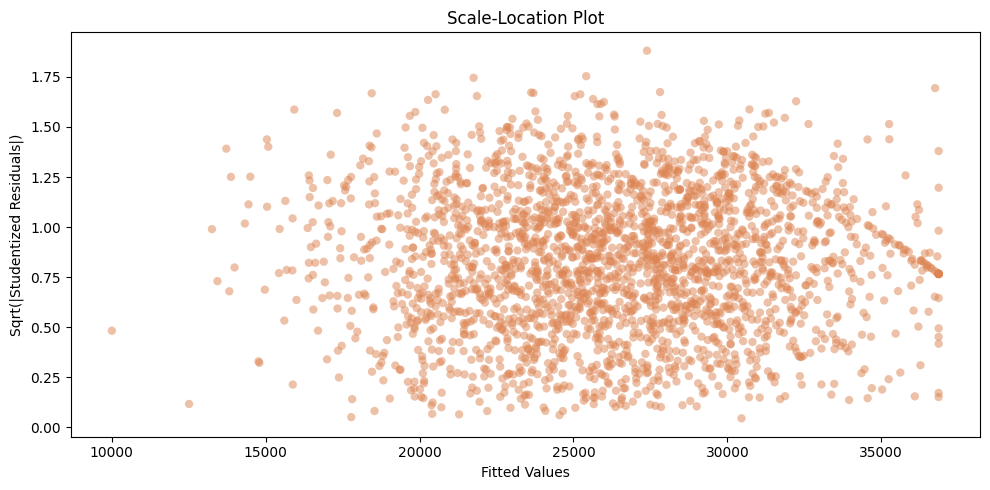

In [12]:
adv_residuals_fit = adv_model.resid
adv_fitted_values = adv_model.fittedvalues
adv_studentized_residuals = adv_model.get_influence().resid_studentized_internal

adv_durbin_watson = sm.stats.stattools.durbin_watson(adv_residuals_fit)
adv_breusch_pagan = het_breuschpagan(adv_residuals_fit, adv_x_train_with_constant)
adv_jarque_bera = sm.stats.stattools.jarque_bera(adv_residuals_fit)

print("Advertising Expenditure assumption checks")
print(f"Durbin-Watson: {adv_durbin_watson:.4f} (values near 2 suggest no autocorrelation)")
print(f"Breusch-Pagan p-value: {adv_breusch_pagan[1]:.6f} (small p-value suggests heteroscedasticity)")
print(f"Jarque-Bera p-value: {adv_jarque_bera[1]:.6f} (small p-value suggests residuals are not approximately normal)")
print(f"Mean residual: {adv_residuals_fit.mean():.6f} (should be close to 0)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(adv_fitted_values, adv_residuals_fit, alpha=0.5, color="#55A868", edgecolors="none")
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("Residuals vs Fitted Values")
axes[0].set_xlabel("Fitted Values")
axes[0].set_ylabel("Residuals")

sm.qqplot(adv_residuals_fit, line="45", ax=axes[1])
axes[1].set_title("Normal Q-Q Plot")

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.scatter(adv_fitted_values, np.sqrt(np.abs(adv_studentized_residuals)), alpha=0.5, color="#DD8452", edgecolors="none")
plt.title("Scale-Location Plot")
plt.xlabel("Fitted Values")
plt.ylabel("Sqrt(|Studentized Residuals|)")
plt.tight_layout()
plt.show()

### Sales vs Avg Customer Rating

This model uses Avg_Customer_Rating as the single predictor for Sales.


                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.194
Model:                            OLS   Adj. R-squared:                  0.194
Method:                 Least Squares   F-statistic:                     576.7
Date:                Thu, 28 May 2026   Prob (F-statistic):          2.23e-114
Time:                        10:19:56   Log-Likelihood:                -24402.
No. Observations:                2400   AIC:                         4.881e+04
Df Residuals:                    2398   BIC:                         4.882e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const               -6.723e+04   3

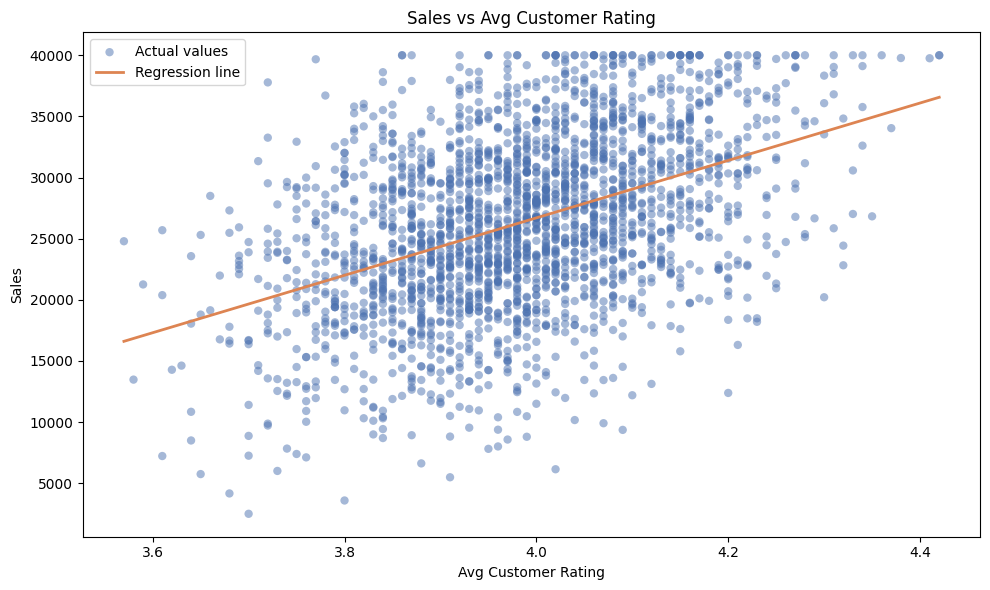

In [14]:
rating_x_train = train_df[["Avg_Customer_Rating"]]
rating_y_train = train_df["Sales"]
rating_x_test = test_df[["Avg_Customer_Rating"]]
rating_y_test = test_df["Sales"]

rating_x_train_with_constant = sm.add_constant(rating_x_train)
rating_x_test_with_constant = sm.add_constant(rating_x_test)

rating_model = sm.OLS(rating_y_train, rating_x_train_with_constant).fit()
rating_predictions = rating_model.predict(rating_x_test_with_constant)

rating_residuals = rating_y_test - rating_predictions
rating_rmse = np.sqrt(np.mean(rating_residuals ** 2))
rating_mae = np.mean(np.abs(rating_residuals))

print(rating_model.summary())
print("\nKey Metrics")
print(f"Intercept: {rating_model.params['const']:.4f}")
print(f"Coefficient for Avg_Customer_Rating: {rating_model.params['Avg_Customer_Rating']:.4f}")
print(f"P-value for Avg_Customer_Rating: {rating_model.pvalues['Avg_Customer_Rating']:.6f}")
print(f"R-squared: {rating_model.rsquared:.4f}")
print(f"F-statistic: {rating_model.fvalue:.4f}")
print(f"RMSE on test set: {rating_rmse:.4f}")
print(f"MAE on test set: {rating_mae:.4f}")

plt.figure(figsize=(10, 6))
plt.scatter(rating_x_train["Avg_Customer_Rating"], rating_y_train, alpha=0.5, color="#4C72B0", edgecolors="none", label="Actual values")
rating_x_line = np.linspace(rating_x_train["Avg_Customer_Rating"].min(), rating_x_train["Avg_Customer_Rating"].max(), 100)
rating_y_line = rating_model.params['const'] + rating_model.params['Avg_Customer_Rating'] * rating_x_line
plt.plot(rating_x_line, rating_y_line, color="#DD8452", linewidth=2, label="Regression line")
plt.title("Sales vs Avg Customer Rating")
plt.xlabel("Avg Customer Rating")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

## Avg Customer Rating Assumption Checks

These checks help us understand whether the Avg_Customer_Rating simple linear regression fit is reasonable.


Avg Customer Rating assumption checks
Durbin-Watson: 1.9673 (values near 2 suggest no autocorrelation)
Breusch-Pagan p-value: 0.081742 (small p-value suggests heteroscedasticity)
Jarque-Bera p-value: 0.004173 (small p-value suggests residuals are not approximately normal)
Mean residual: -0.000000 (should be close to 0)


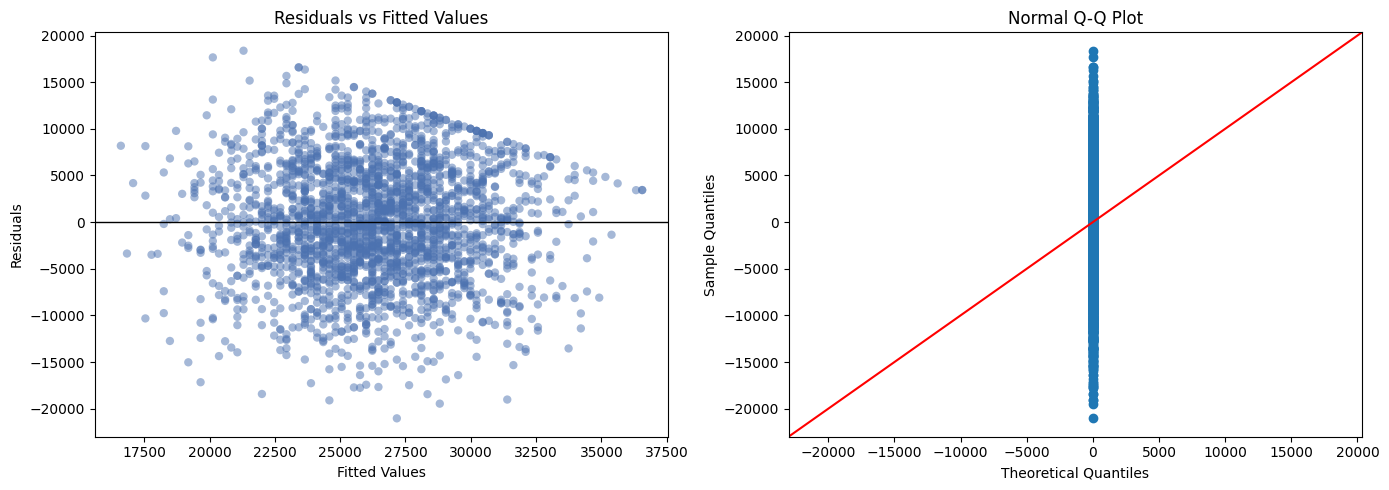

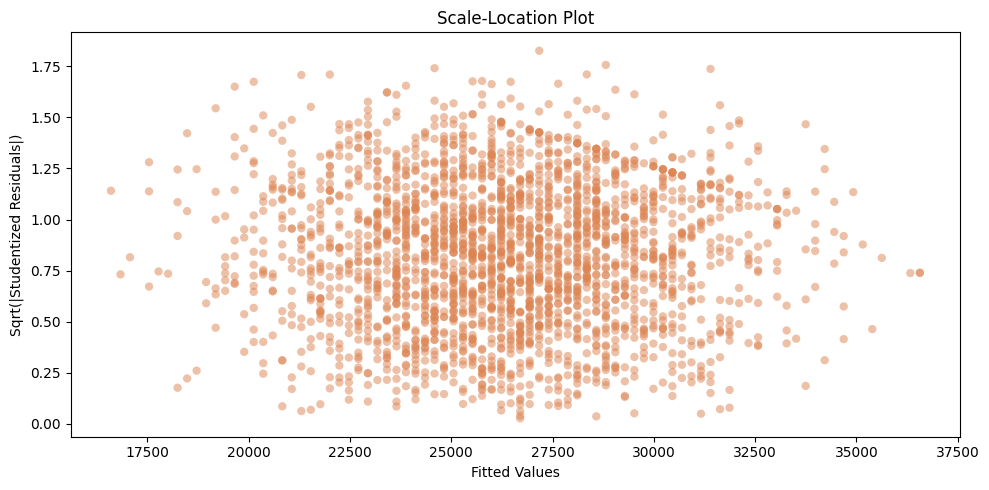

In [16]:
rating_residuals_fit = rating_model.resid
rating_fitted_values = rating_model.fittedvalues
rating_studentized_residuals = rating_model.get_influence().resid_studentized_internal

rating_durbin_watson = sm.stats.stattools.durbin_watson(rating_residuals_fit)
rating_breusch_pagan = het_breuschpagan(rating_residuals_fit, rating_x_train_with_constant)
rating_jarque_bera = sm.stats.stattools.jarque_bera(rating_residuals_fit)

print("Avg Customer Rating assumption checks")
print(f"Durbin-Watson: {rating_durbin_watson:.4f} (values near 2 suggest no autocorrelation)")
print(f"Breusch-Pagan p-value: {rating_breusch_pagan[1]:.6f} (small p-value suggests heteroscedasticity)")
print(f"Jarque-Bera p-value: {rating_jarque_bera[1]:.6f} (small p-value suggests residuals are not approximately normal)")
print(f"Mean residual: {rating_residuals_fit.mean():.6f} (should be close to 0)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(rating_fitted_values, rating_residuals_fit, alpha=0.5, color="#4C72B0", edgecolors="none")
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("Residuals vs Fitted Values")
axes[0].set_xlabel("Fitted Values")
axes[0].set_ylabel("Residuals")

sm.qqplot(rating_residuals_fit, line="45", ax=axes[1])
axes[1].set_title("Normal Q-Q Plot")

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.scatter(rating_fitted_values, np.sqrt(np.abs(rating_studentized_residuals)), alpha=0.5, color="#DD8452", edgecolors="none")
plt.title("Scale-Location Plot")
plt.xlabel("Fitted Values")
plt.ylabel("Sqrt(|Studentized Residuals|)")
plt.tight_layout()
plt.show()

## Model Comparison

The table below compares the three simple linear regression models against a naive baseline.


In [18]:
naive_prediction = train_df["Sales"].mean()
naive_predictions = np.repeat(naive_prediction, len(test_df))
naive_residuals = test_df["Sales"] - naive_predictions
naive_rmse = np.sqrt(np.mean(naive_residuals ** 2))
naive_mae = np.mean(np.abs(naive_residuals))
naive_r2 = 0.0

comparison_rows = [
    {
        "Model": "Naive baseline",
        "Predictor": "Train mean of Sales",
        "Coefficient": np.nan,
        "R2": naive_r2,
        "RMSE": naive_rmse,
        "MAE": naive_mae,
    },
    {
        "Model": "Simple LR",
        "Predictor": "Campaign_Engagement_Score",
        "Coefficient": model.params["Campaign_Engagement_Score"],
        "R2": model.rsquared,
        "RMSE": rmse,
        "MAE": mae,
    },
    {
        "Model": "Simple LR",
        "Predictor": "Advertising_Expenditure",
        "Coefficient": adv_model.params["Advertising_Expenditure"],
        "R2": adv_model.rsquared,
        "RMSE": adv_rmse,
        "MAE": adv_mae,
    },
    {
        "Model": "Simple LR",
        "Predictor": "Avg_Customer_Rating",
        "Coefficient": rating_model.params["Avg_Customer_Rating"],
        "R2": rating_model.rsquared,
        "RMSE": rating_rmse,
        "MAE": rating_mae,
    },
]

comparison_table = pd.DataFrame(comparison_rows)
comparison_table["Coefficient"] = comparison_table["Coefficient"].round(4)
comparison_table["R2"] = comparison_table["R2"].round(4)
comparison_table["RMSE"] = comparison_table["RMSE"].round(4)
comparison_table["MAE"] = comparison_table["MAE"].round(4)
comparison_table


            Model                  Predictor  ...       RMSE        MAE
0  Naive baseline        Train mean of Sales  ...  7249.9877  5818.2165
1       Simple LR  Campaign_Engagement_Score  ...  4999.3751  3992.4250
2       Simple LR    Advertising_Expenditure  ...  5385.1850  4399.9070
3       Simple LR        Avg_Customer_Rating  ...  6491.2529  5124.7081

[4 rows x 6 columns]

## Findings

Document the strongest single-variable models here.

Assumption-check notes:
- Linearity: the residuals vs fitted plot should look randomly scattered around zero.
- Independence: Durbin-Watson near 2 suggests residuals are not autocorrelated.
- Constant variance: the Breusch-Pagan test here suggests mild heteroscedasticity, so interpret standard errors with caution.
- Normality: the Q-Q plot and Jarque-Bera test suggest the residuals are approximately normal.